In [1]:
!git clone 'https://github.com/dphi-official/Datasets/'

Cloning into 'Datasets'...
remote: Enumerating objects: 10246, done.
remote: Counting objects: 100% (99/99), done.
remote: Compressing objects: 100% (74/74), done.
remote: Total 10246 (delta 28), reused 94 (delta 25), pack-reused 10147 (from 1)
Receiving objects: 100% (10246/10246), 557.44 MiB | 31.41 MiB/s, done.
Resolving deltas: 100% (218/218), done.
Updating files: 100% (9441/9441), done.


In [2]:
# To unzip train_beg.zip
!unzip /content/Datasets/animal_data/train_beg.zip

# To unzip test_beg.zip
!unzip /content/Datasets/animal_data/test_beg.zip

Archive:  /content/Datasets/animal_data/train_beg.zip
   creating: train_beg/
  inflating: train_beg/Image_1.jpg   
  inflating: train_beg/Image_10.jpg  
  inflating: train_beg/Image_100.jpg  
  inflating: train_beg/Image_1000.jpg  
  inflating: train_beg/Image_1001.jpg  
  inflating: train_beg/Image_1002.jpg  
  inflating: train_beg/Image_1003.jpg  
  inflating: train_beg/Image_1004.jpg  
  inflating: train_beg/Image_1005.jpg  
  inflating: train_beg/Image_1006.jpg  
  inflating: train_beg/Image_1007.jpg  
  inflating: train_beg/Image_1008.jpg  
  inflating: train_beg/Image_1009.jpg  
  inflating: train_beg/Image_101.jpg  
  inflating: train_beg/Image_1010.jpg  
  inflating: train_beg/Image_1011.jpg  
  inflating: train_beg/Image_1012.jpg  
  inflating: train_beg/Image_1013.jpg  
  inflating: train_beg/Image_1014.jpg  
  inflating: train_beg/Image_1015.jpg  
  inflating: train_beg/Image_1016.jpg  
  inflating: train_beg/Image_1017.jpg  
  inflating: train_beg/Image_1018.jpg  
  inflat

### Loading Libraries

In [3]:
import pandas as pd
import numpy as np

### Loading the Data

In [4]:
train_labels = pd.read_csv("/content/Datasets/animal_data/Training_set_animals.csv")
train_labels.head()


,filename,animal_type
0,Image_1.jpg,mucca
1,Image_2.jpg,mucca
2,Image_3.jpg,mucca
3,Image_4.jpg,mucca
4,Image_5.jpg,mucca


In [5]:
train_labels['animal_type'].value_counts()

,count
animal_type,
mucca,600
pecora,600


Mucca had a value count and pecora also had same meaning that there is no imbalance.

In [7]:
image_paths = ['/content/train_beg/' + fname for fname in train_labels['filename']]
image_paths # will get list of list of image id and image path

"""
The reason behind using the filename from train_labels is that
- it will help you to get all the images whose labels we already have in train_labels.
- It will also help to maintain the order of the images. If you notice the images ids in train_labels, they are
in some specific order, this will help you load all the images location in the list in the same order.
"""

'\nThe reason behind using the filename from train_labels is that\n- it will help you to get all the images whose labels we already have in train_labels.\n- It will also help to maintain the order of the images. If you notice the images ids in train_labels, they are\nin some specific order, this will help you load all the images location in the list in the same order.\n'

In [8]:
train_data = pd.DataFrame({'filename': train_labels['filename'], 'filepath': image_paths, 'animal_type': train_labels['animal_type']})
train_data.head()

,filename,filepath,animal_type
0,Image_1.jpg,/content/train_beg/Image_1.jpg,mucca
1,Image_2.jpg,/content/train_beg/Image_2.jpg,mucca
2,Image_3.jpg,/content/train_beg/Image_3.jpg,mucca
3,Image_4.jpg,/content/train_beg/Image_4.jpg,mucca
4,Image_5.jpg,/content/train_beg/Image_5.jpg,mucca


### Display an image

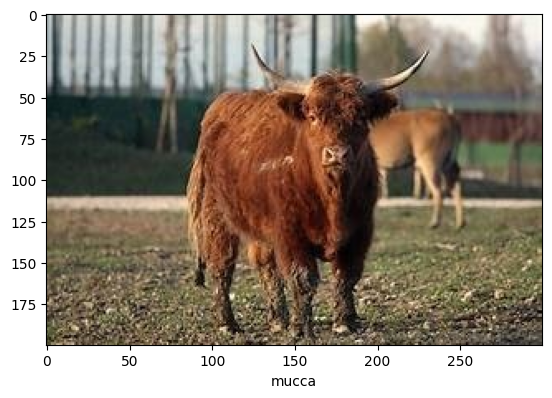

In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image , ImageOps
img = cv2.imread(train_data.iloc[578]['filepath'])
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.xlabel(train_data.iloc[578]['animal_type'])
plt.imshow(img)

In [11]:
import cv2
data = []
labels = []
for i in range (len(train_data)):
  aux = cv2.imread(train_data['filepath'][i])
  image_arr = cv2.cvtColor(aux,cv2.COLOR_BGR2RGB)
  data.append(image_arr)
  if train_data['animal_type'][i] == "mucca":
    labels.append(0)
  else:
    labels.append(1)

array([[[253, 253, 253],
        [253, 253, 253],
        [253, 253, 253],
        ...,
        [151, 155, 166],
        [146, 148, 160],
        [140, 142, 154]],

       [[253, 253, 253],
        [253, 253, 253],
        [253, 253, 253],
        ...,
        [173, 177, 188],
        [171, 175, 186],
        [157, 161, 172]],

       [[253, 253, 253],
        [253, 253, 253],
        [253, 253, 253],
        ...,
        [184, 191, 201],
        [183, 190, 200],
        [167, 174, 184]],

       ...,

       [[182, 185,  82],
        [179, 184,  81],
        [179, 182,  79],
        ...,
        [168, 178,  79],
        [169, 179,  80],
        [170, 180,  81]],

       [[189, 194,  91],
        [178, 185,  81],
        [176, 181,  78],
        ...,
        [165, 175,  78],
        [172, 182,  83],
        [178, 188,  89]],

       [[193, 200,  96],
        [175, 182,  78],
        [169, 176,  72],
        ...,
        [159, 169,  72],
        [165, 175,  76],
        [169, 179,  80]]], dtype=uint8)
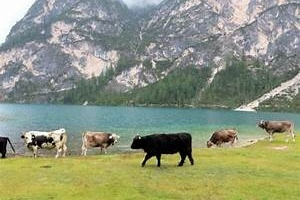

In [ ]:
data[1]

In [13]:
labels[1]

0

### Display image using pixel values

Text(0.5, 0, '0')

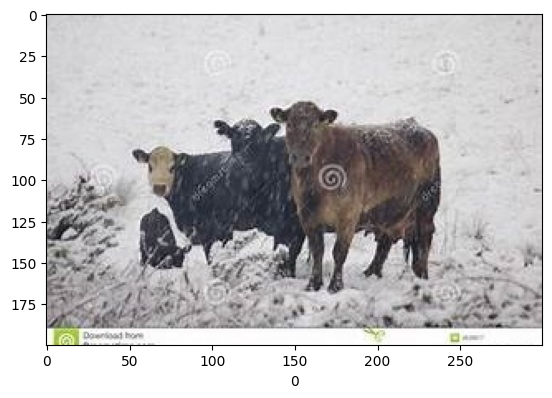

In [14]:
plt.imshow(data[0])
plt.xlabel(labels[0])

In [15]:
labels[0]

0

## Split the Data

In [16]:
from sklearn.model_selection import train_test_split
trainFigures,testFigures,trainlabels,testLabels = train_test_split(data,labels,test_size=0.2,random_state=42)
print(len(trainFigures),len(testFigures))

960 240


### Building Model

In [17]:
import tensorflow as tf
print(tf.__version__)

2.18.0


In [18]:
Input_shape = (200,300,3)
model = tf.keras.Sequential()
model.add(tf.keras.layers.Conv2D(filters=32,kernel_size = (3,3),strides = (1,1),padding = "valid",input_shape = Input_shape,activation = "relu"))
model.add(tf.keras.layers.MaxPooling2D(pool_size =(2,2)))
model.add(tf.keras.layers.Conv2D(filters = 32,kernel_size = (3,3),strides = (1,1),padding = "valid",activation = "relu"))
model.add(tf.keras.layers.MaxPooling2D(pool_size =(2,2)))
model.add(tf.keras.layers.Flatten())
model.add(tf.keras.layers.Dense(128,activation = "relu"))
model.add(tf.keras.layers.Dropout(0.3))
model.add(tf.keras.layers.Dense(1,activation = "sigmoid"))
model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 198, 298, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 99, 149, 32)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 97, 147, 32)         │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 48, 73, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 112128)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │      14,352,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,362,785 (54.79 MB)

 Trainable params: 14,362,785 (54.79 MB)

 Non-trainable params: 0 (0.00 B)

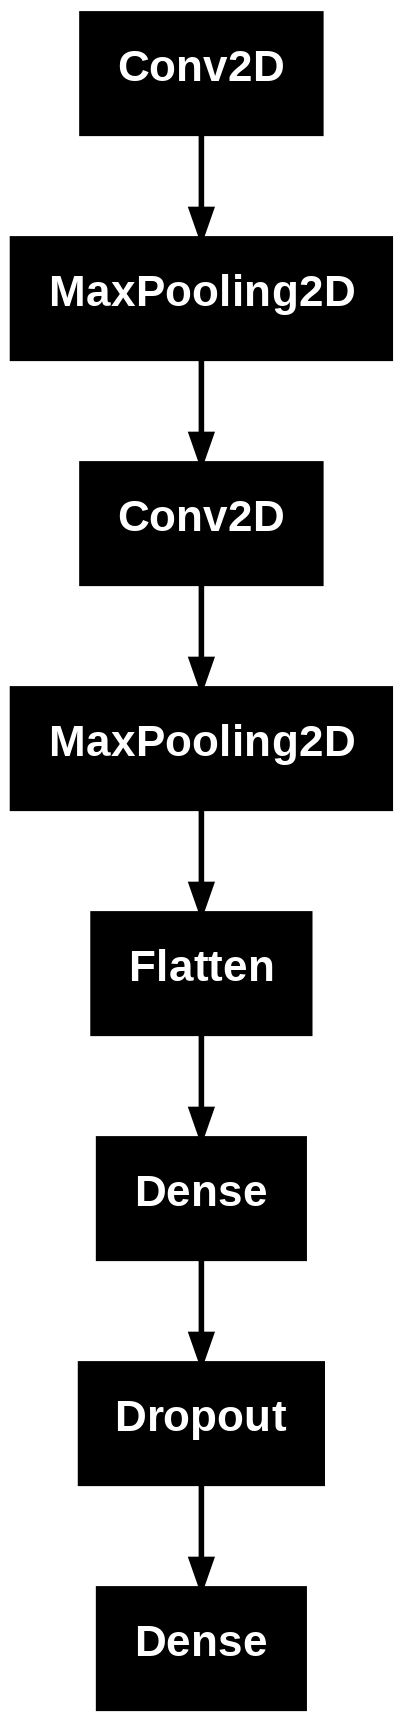

In [19]:
from tensorflow.keras.utils import plot_model
plot_model(model)

### Optimize Model

In [ ]:
print(trainFigures)

[array([[[167, 179, 143],
        [144, 156, 120],
        [140, 152, 116],
        ...,
        [162, 174, 152],
        [172, 184, 164],
        [177, 189, 169]],

       [[202, 213, 179],
        [175, 186, 152],
        [160, 171, 137],
        ...,
        [166, 178, 156],
        [172, 184, 162],
        [175, 187, 165]],

       [[117, 130, 102],
        [127, 140, 110],
        [167, 180, 150],
        ...,
        [161, 173, 149],
        [161, 173, 149],
        [160, 172, 148]],

       ...,

       [[188, 191, 136],
        [176, 179, 124],
        [186, 191, 135],
        ...,
        [190, 198, 121],
        [202, 208, 134],
        [226, 232, 158]],

       [[137, 138,  81],
        [121, 124,  67],
        [142, 147,  89],
        ...,
        [186, 195, 116],
        [210, 214, 138],
        [219, 223, 147]],

       [[105, 106,  48],
        [119, 123,  64],
        [141, 144,  87],
        ...,
        [214, 221, 141],
        [236, 240, 164],
        [244, 246, 171]

In [20]:
train_images_scaled = np.array(trainFigures)/255
test_images_scaled = np.array(testFigures)/255
from tensorflow.keras.callbacks import EarlyStopping
model.compile(optimizer = "adam",loss="binary_crossentropy",metrics = ["accuracy"])
early_callback = EarlyStopping(monitor = "val_loss",patience = 3,restore_best_weights = True)

In [21]:
history = model.fit(train_images_scaled,np.array(trainlabels),epochs = 100,validation_split=0.1,verbose = 1,batch_size = 132, callbacks=[early_callback])


Epoch 1/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 23s 2s/step - accuracy: 0.5594 - loss: 2.8621 - val_accuracy: 0.4792 - val_loss: 1.6503
Epoch 2/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 22s 173ms/step - accuracy: 0.5123 - loss: 1.0496 - val_accuracy: 0.5208 - val_loss: 0.6926
Epoch 3/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 163ms/step - accuracy: 0.5259 - loss: 0.6862 - val_accuracy: 0.5417 - val_loss: 0.6727
Epoch 4/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 175ms/step - accuracy: 0.6409 - loss: 0.6392 - val_accuracy: 0.6042 - val_loss: 0.6330
Epoch 5/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 174ms/step - accuracy: 0.7114 - loss: 0.5696 - val_accuracy: 0.6354 - val_loss: 0.6118
Epoch 6/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 173ms/step - accuracy: 0.7174 - loss: 0.5458 - val_accuracy: 0.7188 - val_loss: 0.5751
Epoch 7/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 173ms/step - accuracy: 0.8366 - loss: 0.4342 - val_accuracy: 0.7917 - val_loss: 0.5275
Epoch 8/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 164ms/step - accuracy: 0.8801 - loss: 0.3269 - val_accuracy: 0.7604 - va

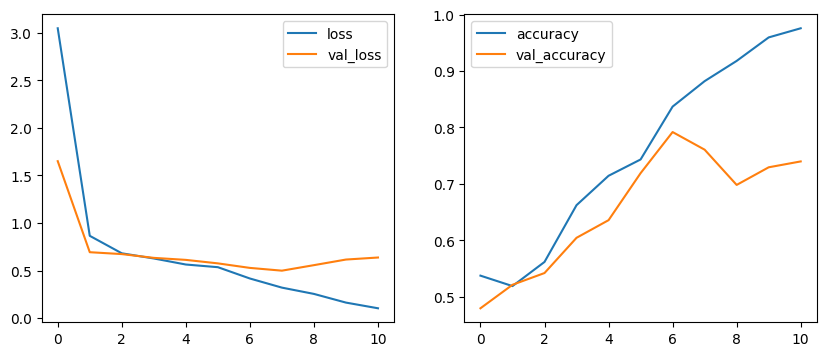

In [22]:
history_df = pd.DataFrame(history.history)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
history_df[['loss', 'val_loss']].plot(kind='line', ax=ax[0])
history_df[['accuracy', 'val_accuracy']].plot(kind='line', ax=ax[1]);

### Prediction

In [23]:
prediction = model.predict(test_images_scaled)

8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 153ms/step


<ipython-input-24-aa0fdb9f187b>:4: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(10,10))


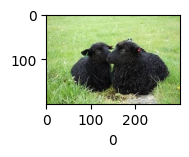

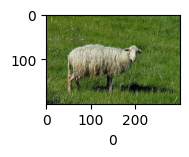

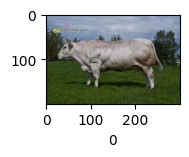

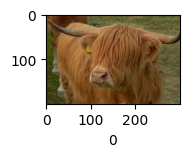

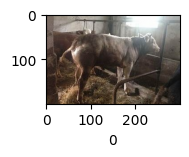

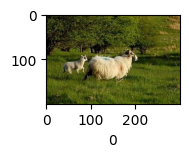

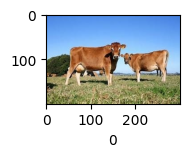

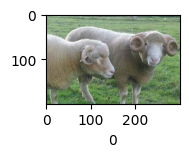

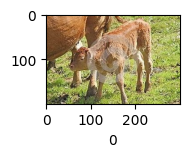

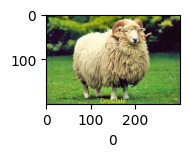

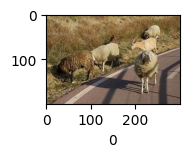

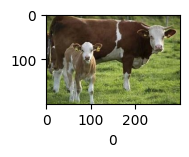

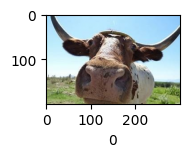

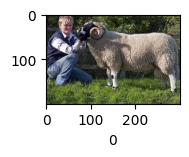

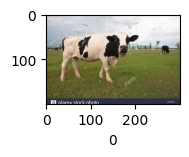

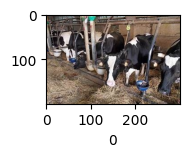

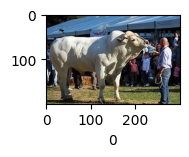

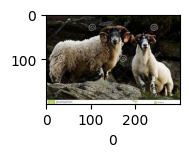

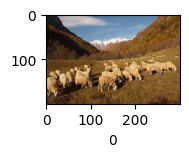

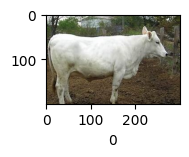

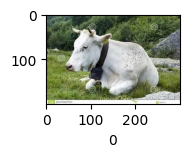

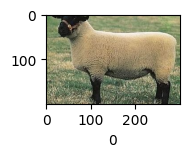

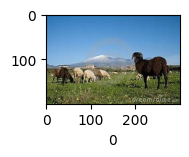

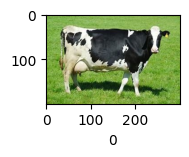

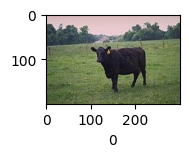

In [24]:
import random
for i in range(25):
  random_no = random.randint(0,len(test_images_scaled))
  plt.figure(figsize=(10,10))
  plt.subplot(5,5,i+1)
  plt.imshow(test_images_scaled[i])
  plt.xlabel(np.argmax(prediction[i]))
plt.show()

### Loading the Test Data

In [25]:
import pandas as pd
test_image_ids = pd.read_csv("/content/Datasets/animal_data/Testing_set_animals.csv",names = ['filename'])
test_image_ids.head()

,filename
0,Image_1.jpg
1,Image_2.jpg
2,Image_3.jpg
3,Image_4.jpg
4,Image_5.jpg


In [29]:
test_data = pd.DataFrame({'filename': test_image_ids['filename'],
                           'filepath': image_paths[:len(test_image_ids)]}) # Slice image_paths to match length of test_image_ids
test_data.head()

,filename,filepath
0,Image_1.jpg,/content/train_beg/Image_1.jpg
1,Image_2.jpg,/content/train_beg/Image_2.jpg
2,Image_3.jpg,/content/train_beg/Image_3.jpg
3,Image_4.jpg,/content/train_beg/Image_4.jpg
4,Image_5.jpg,/content/train_beg/Image_5.jpg


In [31]:
image_pixels = []
for i in range (len(test_data)):
  img_arrray = cv2.imread(test_data['filepath'][i])
  image_pixels.append(image_arr)

In [32]:
test_images_scaled = np.array(image_pixels)/255
pred = model.predict(test_images_scaled)

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step


In [34]:
print(testLabels[180])
print(pred[180])

1
[0.65621024]


1. ### Taking a threshold of 0.5

In [35]:
prediction = []
for value in pred:
  if value < 0.5:
    prediction.append(0)
  else:
    prediction.append(1)

### 2. Using np.round() Function

In [36]:
predictions = np.round(pred)

In [37]:
prediction = []
for item in pred :
  prediction.append(item)